## Visualize data population data and make transformations to see relationships

In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import boxcox
import numpy as np 
from matplotlib import pyplot
from scipy.optimize import curve_fit

In [87]:
#Import data
Pop_res_df=pd.read_csv('..\Clean_data_sets\Merged_pop_reserv_all.csv',index_col=0)

In [88]:
#Create a new column called per capita rate which is the # of reservation divided by the poopulation of the town or city
Pop_res_df['Per_Capita_rate']= Pop_res_df['#_of_reservations']/Pop_res_df['POPESTIMATE2019']

In [89]:
#Drop any null values(City names not matching the US census names )
Pop_res_df = Pop_res_df.dropna(subset=['POPESTIMATE2019'])

In [90]:
#Measure log transformation of the population and per capita
Pop_res_df['POPEST2019LOG'] = np.log(Pop_res_df['POPESTIMATE2019'])
Pop_res_df['Per_Capita_Log'] = np.log(Pop_res_df['Per_Capita_rate'])

In [91]:
#boxcox_array = boxcox(Pop_res_df['POPESTIMATE2019'], lmbda=-0.003922350031296372)
#Pop_res_df['POPEST2019BoxCox'] = boxcox_array.tolist()

In [92]:
Pop_res_df

,city,STNAME,POPESTIMATE2019,#_of_reservations,Per_Capita_rate,POPEST2019LOG,Per_Capita_Log
0,Abbeville,Alabama,2560.0,1,0.000391,7.847763,-7.847763
1,Abbeville,Louisiana,12038.0,2,0.000166,9.395824,-8.702676
2,Abbeville,Mississippi,423.0,2,0.004728,6.047372,-5.354225
3,Abbeville,South Carolina,5014.0,1,0.000199,8.519989,-8.519989
4,Abbot,Maine,677.0,1,0.001477,6.517671,-6.517671
...,...,...,...,...,...,...,...
11373,Zimmerman,Minnesota,5995.0,10,0.001668,8.698681,-6.396096
11374,Zion,Illinois,23487.0,8,0.000341,10.064202,-7.984761
11376,Zionsville,Indiana,28357.0,34,0.001199,10.252629,-6.726269
11378,Zumbro Falls,Minnesota,239.0,8,0.033473,5.476464,-3.397022


In [93]:
#Drop New York as an outlier
print(Pop_res_df.loc[7207])
Pop_res_df = Pop_res_df.drop(7207)

city                    New York
STNAME                  New York
POPESTIMATE2019      1.94536e+07
#_of_reservations            768
Per_Capita_rate      3.94786e-05
POPEST2019LOG            16.7835
Per_Capita_Log          -10.1398
Name: 7207, dtype: object


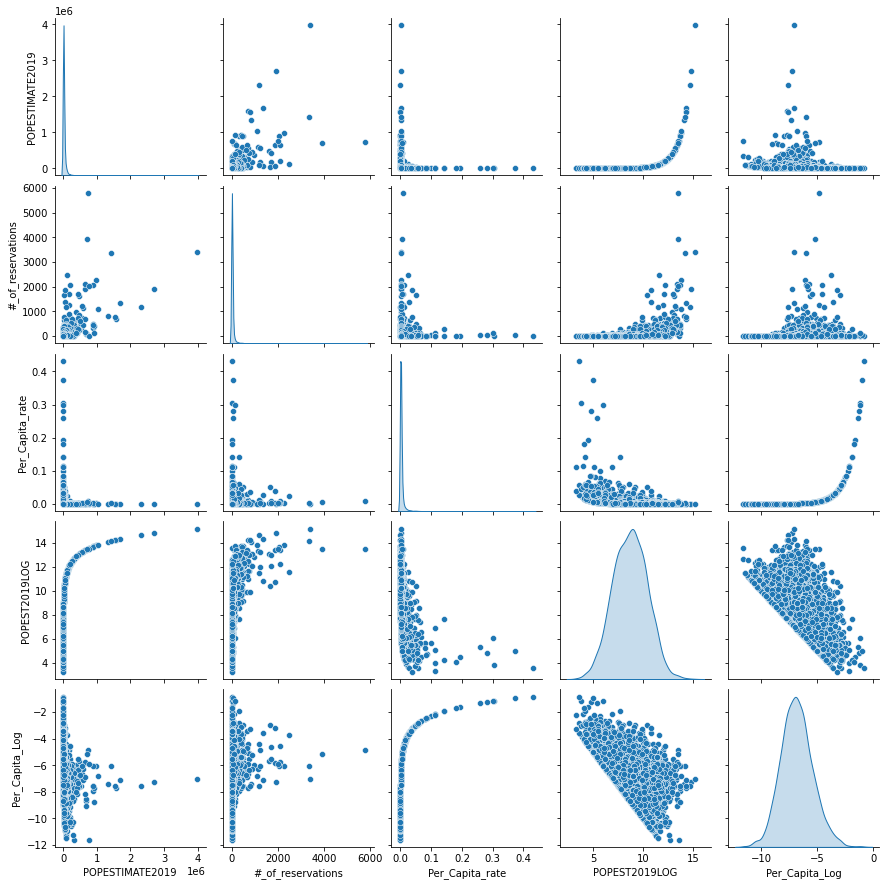

In [94]:
sns.pairplot(Pop_res_df,diag_kind='kde')

<AxesSubplot:xlabel='POPESTIMATE2019', ylabel='#_of_reservations'>

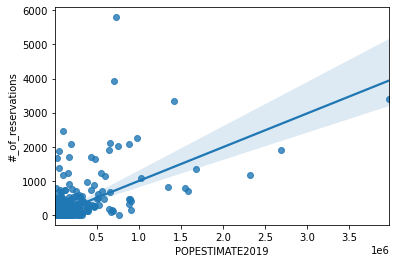

In [95]:
sns.regplot(x='POPESTIMATE2019',y='#_of_reservations',data=Pop_res_df)

<AxesSubplot:xlabel='POPESTIMATE2019', ylabel='Per_Capita_rate'>

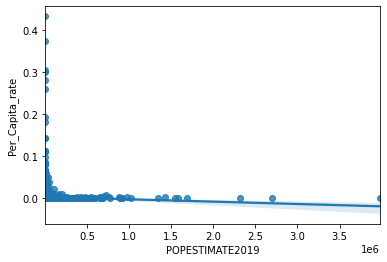

In [97]:
sns.regplot(x='POPESTIMATE2019',y='Per_Capita_rate',data=Pop_res_df)

<AxesSubplot:xlabel='POPEST2019LOG', ylabel='Per_Capita_rate'>

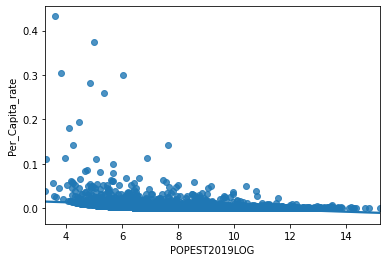

In [50]:
sns.regplot(x='POPEST2019LOG',y='Per_Capita_rate',data=Pop_res_df)

<AxesSubplot:xlabel='POPESTIMATE2019', ylabel='Per_Capita_Log'>

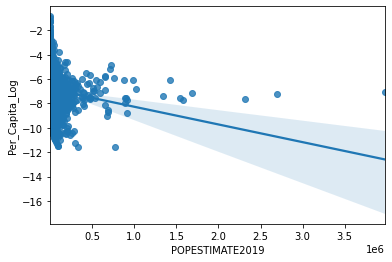

In [75]:
sns.regplot(x='POPESTIMATE2019',y='Per_Capita_Log',data=Pop_res_df)

<AxesSubplot:xlabel='POPEST2019LOG', ylabel='Per_Capita_Log'>

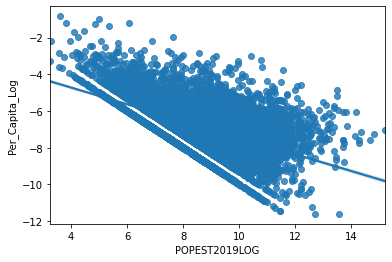

In [96]:
sns.regplot(x='POPEST2019LOG',y='Per_Capita_Log',data=Pop_res_df)

In [10]:
Pop_res_df.loc[Pop_res_df['POPESTIMATE2019'] > 1000000]

,city,STNAME,POPESTIMATE2019,#_of_reservations,Per_Capita_rate
1905,Chicago,Illinois,2693976.0,1911,0.000709
2506,Dallas,Texas,1343573.0,833,0.000620
4804,Houston,Texas,2320268.0,1163,0.000501
5928,Los Angeles,California,3979576.0,3410,0.000857
8020,Philadelphia,Pennsylvania,1584064.0,700,0.000442
8031,Phoenix,Arizona,1680992.0,1346,0.000801
9053,San Antonio,Texas,1547253.0,780,0.000504
9059,San Diego,California,1423851.0,3343,0.002348
9067,San Jose,California,1021795.0,1095,0.001072


In [52]:
def objective(x, a, b, c):
    return a * x + b * x**2 + c

In [56]:
popt, _ = curve_fit(objective, Pop_res_df['POPEST2019LOG'], Pop_res_df['Per_Capita_rate'])

In [57]:
a, b, c = popt
print('y = %.5f * x + %.5f * x^2 + %.5f' % (a, b, c))

y = -0.01851 * x + 0.00094 * x^2 + 0.09041


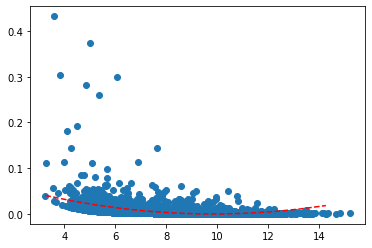

In [60]:
pyplot.scatter(Pop_res_df['POPEST2019LOG'], Pop_res_df['Per_Capita_rate'])
# define a sequence of inputs between the smallest and largest known inputs
x_line = np.arange(min(Pop_res_df['POPEST2019LOG']), max(Pop_res_df['POPEST2019LOG']), 1)
# calculate the output for the range
y_line = objective(x_line, a, b, c)                                              
# create a line plot for the mapping function
pyplot.plot(x_line, y_line, '--', color='red')
pyplot.show()

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(15, 5), sharey=True)
fig.suptitle('')

# 
sns.barplot(ax=axes[0], x=bulbasaur.index, y=bulbasaur.values)
axes[0].set_title(bulbasaur.name)

#
sns.barplot(ax=axes[1], x=charmander.index, y=charmander.values)
axes[1].set_title(charmander.name)

#
sns.barplot(ax=axes[2], x=squirtle.index, y=squirtle.values)
axes[2].set_title(squirtle.name)